# quantforge: a guided tour

`quantforge` is a from-scratch quantitative finance library built on NumPy and SciPy. This notebook walks through its main parts: Black-Scholes analytics, Heston pricing and calibration, American options by three independent methods, Monte Carlo variance reduction, GARCH-based Value-at-Risk with formal backtests, portfolio construction, and a high-frequency alpha research pipeline with a market-making simulation. Wherever possible a result is checked against a published benchmark, a closed form, or a second numerical method.

All randomness is seeded, so re-running the notebook reproduces every number shown. Only wall-clock timings will differ.

**Contents**
1. Black-Scholes prices, Greeks and implied volatility
2. Heston: COS vs Lewis vs the Fang-Oosterlee benchmark, and the implied-vol smile
3. Heston calibration (self-consistency check)
4. American put: PDE vs Leisen-Reimer tree vs Longstaff-Schwartz
5. Monte Carlo variance reduction
6. Risk: GARCH(1,1) VaR and Kupiec / Christoffersen backtests
7. Portfolio construction: efficient frontier, tangency, risk parity
8. Alpha research on a simulated order book
9. Market making with inventory control and an alpha signal
10. Where to go next

## Setup

The library itself needs only NumPy and SciPy; the plots need `matplotlib` (included in the `dev` extra: `pip install -e ".[dev]"`). The small `Table` helper below renders results as HTML tables in Jupyter and on GitHub, and as aligned text elsewhere.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'png'

import time

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

import quantforge as qf
from quantforge import blackscholes as bs
from quantforge import portfolio as pf
from quantforge.alpha import evaluation as ev
from quantforge.alpha import signals as sg
from quantforge.alpha.market_making import simulate_market_maker
from quantforge.alpha.simulate import simulate_book
from quantforge.garch import GarchParams, fit_garch, garch_variance, simulate_garch
from quantforge.heston import HestonParams, calibrate_heston, heston_price
from quantforge.implied_vol import implied_vol
from quantforge.montecarlo import european_mc, longstaff_schwartz
from quantforge.pde import bs_pde
from quantforge.risk import backtest_var
from quantforge.trees import binomial_price

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "figure.figsize": (7.5, 4.2),
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2.0,
    "axes.prop_cycle": plt.cycler(color=COLORS),
})


class Table:
    """Minimal table: HTML in notebooks (and on GitHub), aligned text elsewhere."""

    def __init__(self, headers, rows, fmt="{:.4f}"):
        def cell(c):
            if isinstance(c, str):
                return c
            if isinstance(c, (int, np.integer)):
                return f"{c:,}"
            return fmt.format(c)

        self.headers = list(headers)
        self.rows = [[cell(c) for c in r] for r in rows]

    def _repr_html_(self):
        head = "".join(f"<th>{h}</th>" for h in self.headers)
        body = "".join("<tr>" + "".join(f"<td>{c}</td>" for c in r) + "</tr>" for r in self.rows)
        return f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"

    def __repr__(self):
        cols = list(zip(self.headers, *self.rows))
        w = [max(len(str(x)) for x in col) for col in cols]
        line = lambda r: "  ".join(str(x).rjust(n) for x, n in zip(r, w))
        return "\n".join([line(self.headers), line(["-" * n for n in w])] + [line(r) for r in self.rows])


print(f"quantforge {qf.__version__}, numpy {np.__version__}")

quantforge 1.0.0, numpy 2.5.4


## 1. Black-Scholes prices, Greeks and implied volatility

`blackscholes.greeks` returns the price together with first- and second-order Greeks in closed form, with a continuous dividend yield `q`. Vega and rho are per unit change in volatility and rate (not per 1%), and theta is the calendar-time derivative per year.

In [2]:
S, K, T, r, q, sigma = 100.0, 105.0, 0.5, 0.03, 0.01, 0.25
call = bs.greeks(S, K, T, r, sigma, q, is_call=True)
put = bs.greeks(S, K, T, r, sigma, q, is_call=False)

names = ["price", "delta", "gamma", "vega", "theta", "rho", "vanna", "volga", "charm"]
display(Table(["", "call", "put"], [[n, call[n], put[n]] for n in names]))

parity = call["price"] - put["price"] - (S * np.exp(-q * T) - K * np.exp(-r * T))
print(f"put-call parity residual: {parity:.1e}")

,call,put
price,5.3498,9.2853
delta,0.4456,-0.5494
gamma,0.0223,0.0223
vega,27.8288,27.8288
theta,-7.6880,-5.5799
rho,19.6070,-32.1114
vanna,0.4846,0.4846
volga,4.4901,4.4901
charm,-0.1612,-0.1712


put-call parity residual: 0.0e+00


`implied_vol` inverts the Black-Scholes formula for a whole array of quotes at once, using a Newton iteration safeguarded by a bisection bracket. Below, 10,000 random options (strikes within three standard deviations of the forward, calls and puts mixed) are priced with known volatilities and inverted back.

In [3]:
rng = np.random.default_rng(0)
n = 10_000
T_ = rng.uniform(0.05, 3.0, n)
vol_ = rng.uniform(0.05, 1.0, n)
F_ = S * np.exp((r - q) * T_)
K_ = F_ * np.exp(rng.uniform(-3, 3, n) * vol_ * np.sqrt(T_))
is_call_ = rng.random(n) < 0.5

prices = bs.price(S, K_, T_, r, vol_, q, is_call_)
t0 = time.perf_counter()
iv = implied_vol(prices, S, K_, T_, r, q, is_call_)
elapsed = time.perf_counter() - t0

print(f"{n:,} quotes inverted in {1e3 * elapsed:.0f} ms")
print(f"max |implied vol - true vol| = {np.max(np.abs(iv - vol_)):.1e}, failures (NaN): {np.isnan(iv).sum()}")

10,000 quotes inverted in 30 ms
max |implied vol - true vol| = 3.0e-12, failures (NaN): 0


## 2. Heston: two Fourier pricers and a published benchmark

The Heston model adds a mean-reverting stochastic variance to Black-Scholes. `heston_price` prices European options from the model's characteristic function, either with the COS cosine expansion (fast, a whole strike strip at once) or with Lewis's single-integral formula evaluated by adaptive quadrature (slow, used as a reference). Both are compared with the reference value 5.785155450 for an at-the-money call given by Fang & Oosterlee (2008). These parameters violate the Feller condition, which makes the variance process touch zero and the pricing problem harder.

In [4]:
fo = HestonParams(v0=0.0175, kappa=1.5768, theta=0.0398, sigma=0.5751, rho=-0.5711)
reference = 5.785155450

t0 = time.perf_counter(); cos_v = heston_price(fo, 100.0, 100.0, 1.0, 0.0, 0.0, method="cos"); t_cos = time.perf_counter() - t0
t0 = time.perf_counter(); lew_v = heston_price(fo, 100.0, 100.0, 1.0, 0.0, 0.0, method="lewis"); t_lew = time.perf_counter() - t0

display(Table(
    ["method", "price", "error vs reference", "time (ms)"],
    [["COS (N=2048, L=40)", f"{cos_v:.9f}", f"{cos_v - reference:+.1e}", f"{1e3 * t_cos:.1f}"],
     ["Lewis quadrature", f"{lew_v:.9f}", f"{lew_v - reference:+.1e}", f"{1e3 * t_lew:.1f}"],
     ["Fang & Oosterlee (2008)", f"{reference:.9f}", "", ""]],
))
print(f"Feller ratio 2*kappa*theta/sigma^2 = {fo.feller:.3f} (< 1: condition violated)")

method,price,error vs reference,time (ms)
"COS (N=2048, L=40)",5.785155434,-1.6e-08,3.0
Lewis quadrature,5.785155434,-1.6e-08,2.7
Fang & Oosterlee (2008),5.785155450,,


Feller ratio 2*kappa*theta/sigma^2 = 0.379 (< 1: condition violated)


Converting Heston prices back to Black-Scholes implied volatilities shows the smile the model produces. The negative spot-variance correlation (`rho = -0.57`) skews the smile down to the right, and the skew flattens as maturity grows. Out-of-the-money options are used on each side of the forward.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


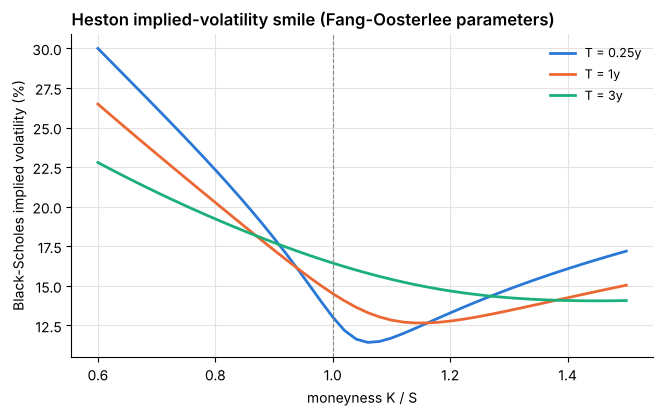

In [5]:
S0 = 100.0
strikes = np.linspace(60, 150, 46)
fig, ax = plt.subplots()
for T_i, color in zip([0.25, 1.0, 3.0], COLORS):
    otm_call = strikes >= S0  # r = q = 0, so the forward equals spot
    px = heston_price(fo, S0, strikes, T_i, 0.0, 0.0, is_call=otm_call)
    vols = implied_vol(px, S0, strikes, T_i, 0.0, 0.0, otm_call)
    ax.plot(strikes / S0, 100 * vols, color=color, label=f"T = {T_i:g}y")
ax.axvline(1.0, color="#8a8984", lw=0.8, ls="--")
ax.set_xlabel("moneyness K / S")
ax.set_ylabel("Black-Scholes implied volatility (%)")
ax.set_title("Heston implied-volatility smile (Fang-Oosterlee parameters)")
ax.legend()
plt.show()

## 3. Heston calibration: recovering known parameters

`calibrate_heston` fits the five parameters to a set of option prices by least squares, weighting each price error by the inverse Black-Scholes vega so that the fit is approximately in implied-volatility units. As a self-consistency check, a 4 x 11 surface is generated from known parameters and the calibrator is started from a deliberately wrong initial guess. It should recover the true parameters up to numerical precision.

In [6]:
S, r, q = 100.0, 0.03, 0.01
true = HestonParams(v0=0.03, kappa=2.5, theta=0.05, sigma=0.6, rho=-0.7)
mats = np.array([0.25, 0.5, 1.0, 2.0])
ks = np.linspace(70, 140, 11)
KK, TT = np.meshgrid(ks, mats)
use_call = KK >= S * np.exp((r - q) * TT)  # quote the out-of-the-money option
market = heston_price(true, S, KK, TT, r, q, use_call)

guess = HestonParams(v0=0.04, kappa=1.0, theta=0.04, sigma=0.3, rho=-0.3)
t0 = time.perf_counter()
cal = calibrate_heston(S, r, q, KK, TT, market, use_call, x0=guess)
elapsed = time.perf_counter() - t0

fields = ["v0", "kappa", "theta", "sigma", "rho"]
display(Table(
    ["parameter", "true", "initial guess", "calibrated", "abs error"],
    [[f, getattr(true, f), getattr(guess, f), getattr(cal.params, f),
      f"{abs(getattr(cal.params, f) - getattr(true, f)):.1e}"] for f in fields],
    fmt="{:.6f}",
))
print(f"{cal.n_quotes} quotes, {cal.nfev} model evaluations, {elapsed:.2f} s, "
      f"implied-vol RMSE {cal.iv_rmse:.1e}, success={cal.success}")

parameter,true,initial guess,calibrated,abs error
v0,0.030000,0.040000,0.030000,1.6e-15
kappa,2.500000,1.000000,2.500000,3.7e-13
theta,0.050000,0.040000,0.050000,6.9e-18
sigma,0.600000,0.300000,0.600000,8.5e-13
rho,-0.700000,-0.300000,-0.700000,7.1e-13


44 quotes, 9 model evaluations, 0.59 s, implied-vol RMSE 3.8e-12, success=True


## 4. American put: three independent methods

The standard test case of Longstaff & Schwartz (2001): a put with S = 36, K = 40, T = 1, r = 6%, sigma = 20%. It is priced by a Crank-Nicolson PDE with a penalty term for early exercise, by a Leisen-Reimer binomial tree, and by least-squares Monte Carlo (LSM). LSM can only exercise on its 50 simulation dates, so it prices a Bermudan option and should be compared with the 50-date Bermudan value (about 4.478, here from a CRR tree), not the continuous American value (about 4.487). The LSM estimate applies the exercise rule fitted on one set of paths to an independent set, so it is a low-biased estimate.

In [7]:
S0, K, T, r, sigma = 36.0, 40.0, 1.0, 0.06, 0.2

european = bs.price(S0, K, T, r, sigma, is_call=False)
pde = bs_pde(S0, K, T, r, sigma, is_call=False, american=True)
lr = binomial_price(S0, K, T, r, sigma, is_call=False, american=True, n_steps=1001, method="lr")
bermudan = binomial_price(S0, K, T, r, sigma, is_call=False, american=True, n_steps=5000,
                          method="crr", exercise_dates=50)
lsm = longstaff_schwartz(S0, K, T, r, sigma, is_call=False, n_exercise=50, n_paths=100_000, seed=7)

display(Table(
    ["method", "exercise", "price", "95% CI"],
    [["Black-Scholes closed form", "European", european, ""],
     ["Crank-Nicolson PDE + penalty (800 x 800)", "American", pde.price, ""],
     ["Leisen-Reimer tree (1001 steps)", "American", lr, ""],
     ["CRR tree (5000 steps)", "Bermudan, 50 dates", bermudan, ""],
     ["Longstaff-Schwartz (100k paths)", "Bermudan, 50 dates", lsm.price,
      f"[{lsm.ci95[0]:.4f}, {lsm.ci95[1]:.4f}]"]],
))
print(f"early-exercise premium (PDE - European): {pde.price - european:.4f}")
print(f"PDE delta {pde.delta:.4f}, gamma {pde.gamma:.4f}")

method,exercise,price,95% CI
Black-Scholes closed form,European,3.8443,
Crank-Nicolson PDE + penalty (800 x 800),American,4.4866,
Leisen-Reimer tree (1001 steps),American,4.4862,
CRR tree (5000 steps),"Bermudan, 50 dates",4.4779,
Longstaff-Schwartz (100k paths),"Bermudan, 50 dates",4.4727,"[4.4609, 4.4844]"


early-exercise premium (PDE - European): 0.6423
PDE delta -0.6968, gamma 0.0867


## 5. Monte Carlo variance reduction

The same European call (S = K = 100, T = 1, r = 5%, sigma = 20%) is priced with 65,536 paths per method, so the standard errors are directly comparable. Antithetic variates pair each draw with its negative; the control variate uses the discounted terminal stock, whose expectation is known exactly; Sobol RQMC uses 16 independently scrambled Sobol sequences and takes its standard error from the spread of the 16 replicate means. "Variance reduction" is the plain-MC variance divided by the method's variance at equal path count.

In [8]:
S0, K, T, r, sigma = 100.0, 100.0, 1.0, 0.05, 0.2
exact = bs.price(S0, K, T, r, sigma)
N = 2**16
args = (S0, K, T, r, sigma)

runs = {
    "plain": european_mc(*args, n_paths=N, seed=1),
    "antithetic": european_mc(*args, n_paths=N, seed=1, antithetic=True),
    "control variate": european_mc(*args, n_paths=N, seed=1, control_variate=True),
    "antithetic + control variate": european_mc(*args, n_paths=N, seed=1, antithetic=True, control_variate=True),
    "Sobol RQMC (16 x 4,096)": european_mc(*args, n_paths=N, seed=1, method="sobol", qmc_reps=16),
}
base = runs["plain"].stderr
display(Table(
    ["method", "price", "std error", "error / std error", "variance reduction"],
    [[name, res.price, f"{res.stderr:.5f}", f"{(res.price - exact) / res.stderr:+.2f}",
      f"{(base / res.stderr) ** 2:,.0f}x"] for name, res in runs.items()],
))
print(f"Black-Scholes closed form: {exact:.4f}")

method,price,std error,error / std error,variance reduction
plain,10.3074,0.05724,-2.50,1x
antithetic,10.3575,0.04020,-2.32,2x
control variate,10.4230,0.02189,-1.26,7x
antithetic + control variate,10.3824,0.03030,-2.25,4x
"Sobol RQMC (16 x 4,096)",10.4508,0.00051,+0.34,"12,826x"


Black-Scholes closed form: 10.4506


## 6. Risk: GARCH(1,1) Value-at-Risk and backtests

Daily returns are simulated from a GARCH(1,1) process with known parameters. The model is fitted by quasi-maximum likelihood on the first 1,500 days, and its parameters are then frozen to produce one-day-ahead 99% VaR forecasts for the next 3,000 days. A 250-day historical-simulation VaR is the benchmark. `backtest_var` runs Kupiec's test of the breach frequency, Christoffersen's test that breaches are not clustered, and the joint conditional-coverage test.

In [9]:
true_g = GarchParams(mu=0.0002, omega=3e-6, alpha=0.09, beta=0.89)
n_train, n_test, window = 1500, 3000, 250
ret, _ = simulate_garch(true_g, n_train + n_test, seed=21)

fit = fit_garch(ret[:n_train])
p = fit.params
display(Table(
    ["parameter", "true", "fitted", "std error"],
    [[f, getattr(true_g, f), getattr(p, f), fit.stderr[f]] for f in ["mu", "omega", "alpha", "beta"]],
    fmt="{:.3g}",
))
print(f"fitted persistence alpha+beta = {p.persistence:.4f}, variance half-life = {p.half_life:.1f} days")

# One-step-ahead conditional variance over the whole sample; sigma2[t] uses returns up to t-1 only.
eps = ret - p.mu
sigma2, _ = garch_variance(eps, p.omega, p.alpha, p.beta, eps[:n_train].var())
test = ret[n_train:]
z99 = norm.ppf(0.99)
var_garch = -p.mu + z99 * np.sqrt(sigma2[n_train:])
hist_windows = np.lib.stride_tricks.sliding_window_view(ret[n_train - window:-1], window)
var_hist = -np.quantile(hist_windows, 0.01, axis=1)

bt = {"GARCH(1,1), Gaussian": backtest_var(test, var_garch, 0.99),
      "historical simulation, 250d": backtest_var(test, var_hist, 0.99)}
display(Table(
    ["99% VaR model", "breaches", "expected", "Kupiec p", "Christoffersen p", "cond. coverage p"],
    [[k, b.n_exceptions, f"{b.expected:.0f}", b.p_pof, b.p_ind, b.p_cc] for k, b in bt.items()],
    fmt="{:.3f}",
))

parameter,true,fitted,std error
mu,0.0002,0.000362,0.000242
omega,3e-06,2.08e-06,8.21e-07
alpha,0.09,0.103,0.0161
beta,0.89,0.884,0.0182


fitted persistence alpha+beta = 0.9869, variance half-life = 52.4 days


99% VaR model,breaches,expected,Kupiec p,Christoffersen p,cond. coverage p
"GARCH(1,1), Gaussian",31,30,0.855,0.421,0.711
"historical simulation, 250d",38,30,0.159,0.012,0.016


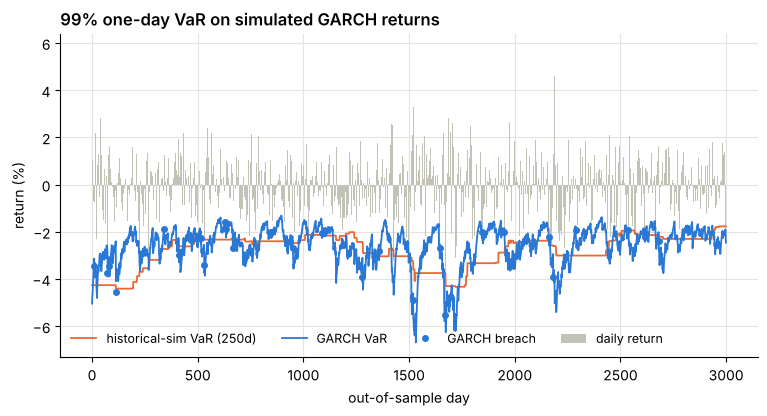

In [10]:
days = np.arange(n_test)
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(days, 100 * test, width=1.0, color="#c3c2b7", label="daily return")
ax.plot(days, -100 * var_hist, color=COLORS[1], lw=1.3, label="historical-sim VaR (250d)")
ax.plot(days, -100 * var_garch, color=COLORS[0], lw=1.3, label="GARCH VaR")
hit = test < -var_garch
ax.plot(days[hit], 100 * test[hit], "o", ms=4, color=COLORS[0], label="GARCH breach")
ax.set_xlabel("out-of-sample day")
ax.set_ylabel("return (%)")
ax.set_title("99% one-day VaR on simulated GARCH returns")
ax.legend(loc="lower left", ncol=4)
plt.show()

## 7. Portfolio construction

A five-asset example with assumed annual expected returns, volatilities and correlations. The efficient frontier is computed in closed form without constraints and by SLSQP with a long-only constraint. The plot marks the long-only global minimum-variance portfolio, the long-only tangency (maximum Sharpe) portfolio for a 2% risk-free rate, and the equal-risk-contribution (risk parity) portfolio.

In [11]:
assets = ["US equity", "Intl equity", "Govt bonds", "Credit", "Gold"]
mu = np.array([0.075, 0.070, 0.030, 0.045, 0.050])
vols = np.array([0.16, 0.18, 0.06, 0.08, 0.15])
corr = np.array([
    [1.00, 0.80, -0.20, 0.40, 0.05],
    [0.80, 1.00, -0.15, 0.40, 0.05],
    [-0.20, -0.15, 1.00, 0.50, 0.25],
    [0.40, 0.40, 0.50, 1.00, 0.15],
    [0.05, 0.05, 0.25, 0.15, 1.00],
])
cov = np.outer(vols, vols) * corr
rf = 0.02

ret_u, vol_u, _ = pf.efficient_frontier(mu, cov, n_points=100)
ret_l, vol_l, _ = pf.efficient_frontier(mu, cov, n_points=40, long_only=True)
ports = {
    "min variance": pf.min_variance(cov, long_only=True),
    "tangency": pf.tangency(mu, cov, rf, long_only=True),
    "risk parity": pf.risk_parity(cov),
}
stats_ = {k: (w @ mu, np.sqrt(w @ cov @ w)) for k, w in ports.items()}

rows = [[a] + [f"{100 * w[i]:.1f}%" for w in ports.values()] for i, a in enumerate(assets)]
rows.append(["expected return"] + [f"{100 * m:.2f}%" for m, _ in stats_.values()])
rows.append(["volatility"] + [f"{100 * s:.2f}%" for _, s in stats_.values()])
rows.append(["Sharpe ratio"] + [f"{(m - rf) / s:.3f}" for m, s in stats_.values()])
display(Table(["weight"] + list(ports), rows))
rc = pf.risk_contributions(ports["risk parity"], cov)
print("risk parity contributions to variance:", ", ".join(f"{a} {100 * c:.1f}%" for a, c in zip(assets, rc)))

weight,min variance,tangency,risk parity
US equity,15.0%,31.9%,12.6%
Intl equity,1.5%,0.0%,10.9%
Govt bonds,80.7%,41.2%,41.0%
Credit,0.0%,13.9%,20.2%
Gold,2.9%,13.0%,15.4%
expected return,3.79%,4.90%,4.61%
volatility,5.16%,6.59%,6.22%
Sharpe ratio,0.347,0.440,0.420


risk parity contributions to variance: US equity 20.0%, Intl equity 20.0%, Govt bonds 20.0%, Credit 20.0%, Gold 20.0%


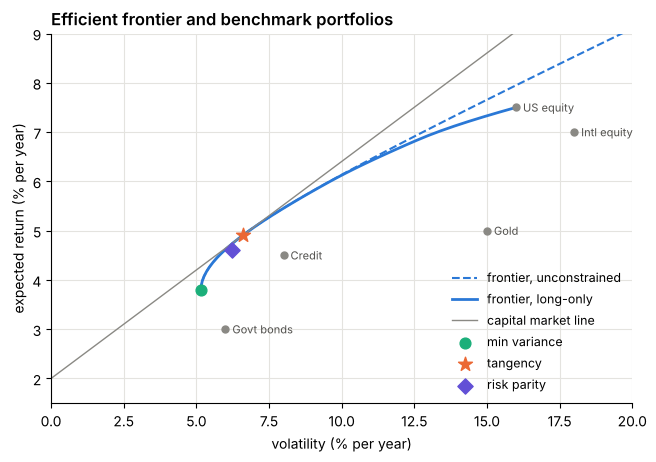

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(100 * vol_u, 100 * ret_u, color=COLORS[0], lw=1.5, ls="--", label="frontier, unconstrained")
ax.plot(100 * vol_l, 100 * ret_l, color=COLORS[0], label="frontier, long-only")
ax.scatter(100 * vols, 100 * mu, color="#8a8984", s=25, zorder=3)
for a, v, m in zip(assets, vols, mu):
    ax.annotate(a, (100 * v, 100 * m), xytext=(5, -3), textcoords="offset points", fontsize=8, color="#52514e")
m_t, s_t = stats_["tangency"]
xs = np.linspace(0, 100 * vols.max(), 2)
ax.plot(xs, 100 * rf + (m_t - rf) / s_t * xs, color="#8a8984", lw=1, label="capital market line")
for (name, (m, s)), c, mk in zip(stats_.items(), [COLORS[2], COLORS[1], COLORS[4]], ["o", "*", "D"]):
    ax.scatter(100 * s, 100 * m, color=c, marker=mk, s=110 if mk == "*" else 60, zorder=4, label=name)
ax.set_xlim(0, 100 * vols.max() + 2)
ax.set_ylim(1.5, 100 * mu.max() + 1.5)
ax.set_xlabel("volatility (% per year)")
ax.set_ylabel("expected return (% per year)")
ax.set_title("Efficient frontier and benchmark portfolios")
ax.legend(loc="lower right")
plt.show()

## 8. Alpha research on a simulated order book

> **Simulated data.** Everything in this section uses `simulate_book`, a synthetic limit order book into which a known alpha was planted on purpose: order-book imbalance and an unobservable informed-flow state (which leaks into trade signs) drive the next mid-price move. The planted effect is deliberately strong. The point is to validate the pipeline where the right answer is known, not to claim an edge on real markets. A second book with zero alpha is used as a control.

Two signals are computed causally: level-1 book imbalance `(Qb - Qa) / (Qb + Qa)` and trade-flow imbalance over the last 50 steps.

In [13]:
book = simulate_book(n_steps=200_000, seed=1)
null_book = simulate_book(n_steps=200_000, beta=0.0, gamma=0.0, kappa=0.0, seed=2)  # zero-alpha control
mid = book.mid

signals = {
    "book imbalance": sg.book_imbalance(book.bid_qty, book.ask_qty),
    "trade-flow imbalance (50)": sg.trade_flow_imbalance(book.buy_vol, book.sell_vol, 50),
}
print(f"{len(book):,} steps, tick {book.tick}, mid from {mid.min():.2f} to {mid.max():.2f}")

200,000 steps, tick 0.01, mid from 97.21 to 102.97


`ic_decay` reports, for each forecast horizon h, the information coefficient (correlation of the signal with the next-h-step mid return) and the t-statistic of the predictive regression. Because h-step returns sampled every step overlap, ordinary OLS t-statistics are badly inflated; Newey-West standard errors with h lags correct for that overlap. The gap between the two columns is the main point of this table.

In [14]:
horizons = [1, 5, 20, 50, 200]
decay = {name: ev.ic_decay(x, mid, horizons) for name, x in signals.items()}
null_decay = ev.ic_decay(sg.trade_flow_imbalance(null_book.buy_vol, null_book.sell_vol, 50), null_book.mid, horizons)

rows = []
for name, res in {**decay, "trade-flow imb., zero-alpha book": null_decay}.items():
    for row in res:
        rows.append([name, row["horizon"], f"{row['ic']:.3f}", f"{row['rank_ic']:.3f}",
                     f"{row['t_naive']:.1f}", f"{row['t_nw']:.1f}"])
display(Table(["signal", "horizon (steps)", "IC", "rank IC", "naive t", "Newey-West t"], rows))

signal,horizon (steps),IC,rank IC,naive t,Newey-West t
book imbalance,1,0.057,0.057,25.4,25.2
book imbalance,5,0.115,0.112,51.8,27.0
book imbalance,20,0.166,0.162,75.2,21.0
book imbalance,50,0.152,0.150,68.8,13.2
book imbalance,200,0.064,0.068,28.6,4.0
trade-flow imbalance (50),1,0.102,0.101,45.8,45.8
trade-flow imbalance (50),5,0.219,0.214,100.3,52.1
trade-flow imbalance (50),20,0.384,0.376,186.1,49.1
trade-flow imbalance (50),50,0.493,0.486,253.4,42.5
trade-flow imbalance (50),200,0.511,0.506,265.8,24.4


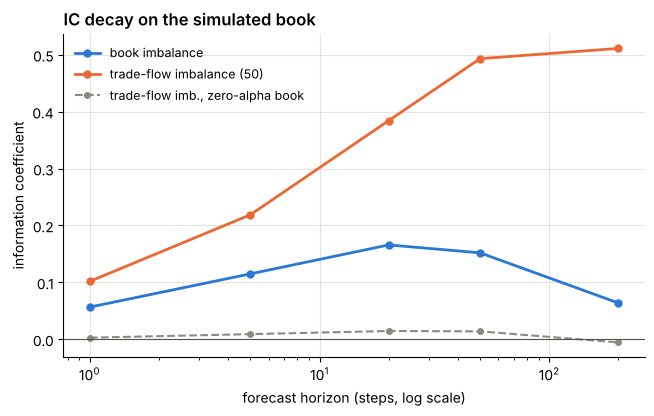

In [15]:
fig, ax = plt.subplots()
for (name, res), c in zip(decay.items(), COLORS):
    ax.semilogx(horizons, [row["ic"] for row in res], "-o", ms=5, color=c, label=name)
ax.semilogx(horizons, [row["ic"] for row in null_decay], "--o", ms=4, color="#8a8984", lw=1.5,
            label="trade-flow imb., zero-alpha book")
ax.axhline(0, color="#52514e", lw=0.8)
ax.set_xlabel("forecast horizon (steps, log scale)")
ax.set_ylabel("information coefficient")
ax.set_title("IC decay on the simulated book")
ax.legend()
plt.show()

The signals are then combined by ridge regression in a five-fold expanding walk-forward: each fold is fitted only on earlier data, standardised with training statistics, and separated from its test block by an embargo equal to the 10-step label horizon so no training label overlaps the test period. `taker_backtest` trades the sign of the out-of-sample forecast with market orders every 10 steps, paying the half-spread; the break-even fee is the per-trade fee at which net P&L would be zero.

In [16]:
H = 10

def features(b):
    return np.column_stack([
        sg.book_imbalance(b.bid_qty, b.ask_qty),
        sg.order_flow_imbalance(b.bid, b.ask, b.bid_qty, b.ask_qty, 20),
        sg.trade_flow_imbalance(b.buy_vol, b.sell_vol, 50),
        sg.past_return_bps(b.mid, 50),
    ])

rows = []
for label, b in [("planted alpha", book), ("zero alpha (control)", null_book)]:
    y = ev.forward_return_bps(b.mid, H)
    yhat, coefs = ev.walk_forward_ridge(features(b), y, horizon=H, n_folds=5, lam=1.0)
    bt0 = ev.taker_backtest(yhat, b.bid, b.ask, H, threshold_bps=0.0, fee_bps=0.0)
    rows.append([label, f"{ev.oos_r2(y, yhat):.4f}", f"{bt0.hit_rate:.3f}", f"{bt0.gross_bps.mean():.4f}",
                 f"{bt0.breakeven_fee_bps:.3f}"])
display(Table(["market", "OOS R^2 (h=10)", "hit rate", "gross bps / period", "break-even fee (bps)"], rows))
half_spread = 0.5 * book.tick / mid.mean() * 1e4
print(f"half-spread on this book: {half_spread:.2f} bps; a typical crypto taker fee is ~5 bps")

market,OOS R^2 (h=10),hit rate,gross bps / period,break-even fee (bps)
planted alpha,0.1123,0.443,0.2941,1.383
zero alpha (control),-0.0002,0.326,0.0076,-0.474


half-spread on this book: 0.50 bps; a typical crypto taker fee is ~5 bps


## 9. Market making with inventory control and an alpha signal

`simulate_market_maker` runs an Avellaneda-Stoikov dealer. The mid price has a mean-reverting drift `alpha`, and order flow is informed: buyers arrive faster when `alpha > 0`, so a dealer that ignores alpha is adversely selected. Three strategies share the same random numbers: quotes centred on the mid (`symmetric`), the Avellaneda-Stoikov inventory-adjusted reservation price (`inventory`), and the reservation price also shifted by the expected drift (`alpha`). P&L is in price units per simulated session (2,000 sessions).

In [17]:
mm_kw = dict(n_sims=2000, seed=2, alpha_sd=2.0, informed=0.5)
mm = {
    "symmetric": simulate_market_maker("symmetric", **mm_kw),
    "inventory (Avellaneda-Stoikov)": simulate_market_maker("inventory", **mm_kw),
    "alpha, noisy signal (corr 0.3)": simulate_market_maker("alpha", signal_corr=0.3, **mm_kw),
    "alpha, perfect signal (corr 1.0)": simulate_market_maker("alpha", signal_corr=1.0, **mm_kw),
}
rows = []
for name, res in mm.items():
    s = res.summary()
    rows.append([name, s["mean_pnl"], s["std_pnl"], s["sharpe"], s["std_final_q"], f"{s['mean_fills']:.0f}"])
display(Table(["strategy", "mean P&L", "sd P&L", "Sharpe", "sd final inventory", "mean fills"], rows, fmt="{:.2f}"))

strategy,mean P&L,sd P&L,Sharpe,sd final inventory,mean fills
symmetric,65.68,84.58,0.78,58.41,121
inventory (Avellaneda-Stoikov),69.34,12.37,5.61,15.15,97
"alpha, noisy signal (corr 0.3)",68.84,12.12,5.68,14.90,97
"alpha, perfect signal (corr 1.0)",70.17,9.84,7.13,12.18,91


Inventory control mainly cuts risk: the P&L standard deviation and the end-of-session inventory both fall. The large jump in mean P&L from the alpha strategy requires a perfect view of the drift. With a signal that is only 0.3 correlated with the true drift, which is closer to what real signals offer, the improvement over the inventory strategy is much smaller.

## 10. Where to go next

- [`docs/ALPHA.md`](../docs/ALPHA.md): a from-zero guide to the alpha module, covering signal formulas, IC and Newey-West inference, walk-forward fitting, costs, deflated Sharpe ratios and market making, plus how to run the pipeline on real Binance data.
- [`docs/RESULTS.md`](../docs/RESULTS.md): the full validation table, with every model checked against a closed form, a published benchmark or an independent method.
- `examples/showcase.py` and `examples/alpha_research.py` regenerate those reports and figures; `pytest` runs the test-suite.